# Notebook 3: Machine Learning for Book Rating Prediction

## Research objective
Investigate whether book metadata can predict whether a reader gives a book a high rating using the Goodbooks-10k dataset.

### Research questions
1. How well can a model classify ratings as high versus not high?
2. How does a trained model compare with a simple baseline?
3. Which available book features contribute to prediction?

### Methodology
- Load and inspect the processed ratings and book metadata.
- Define a binary target: high rating = rating 4 or 5; not high = rating 1, 2, or 3.
- Join rating records to book metadata.
- Exclude direct identifiers and rating aggregates that could leak target information.
- Split into training and test sets.
- Train a majority-class baseline and Logistic Regression.
- Evaluate accuracy, precision, recall, F1-score, ROC-AUC, and a confusion matrix.
- Save results and configuration.

**Scope note:** this is a metadata-based rating classification experiment, not a fully personalized recommender. A random record split may place the same books in both training and testing sets, so results should not be interpreted as performance on entirely unseen books.


## 1. Set up paths and imports

This cell locates your project folder by searching for `data/processed/ratings_model.csv`.

In [1]:
from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, ConfusionMatrixDisplay
)

warnings.filterwarnings("ignore", category=FutureWarning)

current = Path.cwd()
candidates = [current, *current.parents]
PROJECT_ROOT = next(
    (p for p in candidates
     if (p / "data" / "processed" / "ratings_model.csv").exists()),
    None
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Cannot locate data/processed/ratings_model.csv. "
        "Open/run this notebook from inside goodbooks-graph-research."
    )

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
OUTPUT_DIR = PROJECT_ROOT / "outputs"
TABLES_DIR = OUTPUT_DIR / "tables"
FIGURES_DIR = OUTPUT_DIR / "figures"
TABLES_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42
MAX_ROWS = 200_000  # Set to None to use all rows; this may take longer.

print("Project root:", PROJECT_ROOT)
print("Processed data:", PROCESSED_DIR)
print("Output tables:", TABLES_DIR)


Project root: c:\Users\Nethmi\Desktop\goodbooks-graph-research
Processed data: c:\Users\Nethmi\Desktop\goodbooks-graph-research\data\processed
Output tables: c:\Users\Nethmi\Desktop\goodbooks-graph-research\outputs\tables


## 2. Load and inspect processed datasets

In [2]:
ratings_path = PROCESSED_DIR / "ratings_model.csv"
books_path = PROCESSED_DIR / "books_clean.csv"

if not ratings_path.exists():
    raise FileNotFoundError(f"Missing file: {ratings_path}")
if not books_path.exists():
    raise FileNotFoundError(f"Missing file: {books_path}")

ratings_df = pd.read_csv(ratings_path)
books_df = pd.read_csv(books_path)

print("Ratings shape:", ratings_df.shape)
print("Ratings columns:", ratings_df.columns.tolist())
display(ratings_df.head())

print("\\nBooks shape:", books_df.shape)
print("Books columns:", books_df.columns.tolist())
display(books_df.head())

print("\\nRatings missing values (top 15):")
display(ratings_df.isna().sum().sort_values(ascending=False).head(15))
print("\\nBooks missing values (top 15):")
display(books_df.isna().sum().sort_values(ascending=False).head(15))


Ratings shape: (980112, 9)
Ratings columns: ['user_id', 'book_id', 'rating', 'positive_rating', 'title', 'authors', 'language_code', 'average_rating', 'ratings_count']


,user_id,book_id,rating,positive_rating,title,authors,language_code,average_rating,ratings_count
0,314,1,5,1,"The Hunger Games (The Hunger Games, #1)",Suzanne Collins,eng,4.34,4780653
1,439,1,3,0,"The Hunger Games (The Hunger Games, #1)",Suzanne Collins,eng,4.34,4780653
2,588,1,5,1,"The Hunger Games (The Hunger Games, #1)",Suzanne Collins,eng,4.34,4780653
3,1169,1,4,1,"The Hunger Games (The Hunger Games, #1)",Suzanne Collins,eng,4.34,4780653
4,1185,1,4,1,"The Hunger Games (The Hunger Games, #1)",Suzanne Collins,eng,4.34,4780653


\nBooks shape: (10000, 23)
Books columns: ['id', 'book_id', 'best_book_id', 'work_id', 'books_count', 'isbn', 'isbn13', 'authors', 'original_publication_year', 'original_title', 'title', 'language_code', 'average_rating', 'ratings_count', 'work_ratings_count', 'work_text_reviews_count', 'ratings_1', 'ratings_2', 'ratings_3', 'ratings_4', 'ratings_5', 'image_url', 'small_image_url']


,id,book_id,best_book_id,work_id,books_count,isbn,isbn13,authors,original_publication_year,original_title,...,ratings_count,work_ratings_count,work_text_reviews_count,ratings_1,ratings_2,ratings_3,ratings_4,ratings_5,image_url,small_image_url
0,1,2767052,2767052,2792775,272,439023483,9.780439e+12,Suzanne Collins,2008.0,The Hunger Games,...,4780653,4942365,155254,66715,127936,560092,1481305,2706317,https://images.gr-assets.com/books/1447303603m...,https://images.gr-assets.com/books/1447303603s...
1,2,3,3,4640799,491,439554934,9.780440e+12,"J.K. Rowling, Mary GrandPré",1997.0,Harry Potter and the Philosopher's Stone,...,4602479,4800065,75867,75504,101676,455024,1156318,3011543,https://images.gr-assets.com/books/1474154022m...,https://images.gr-assets.com/books/1474154022s...
2,3,41865,41865,3212258,226,316015849,9.780316e+12,Stephenie Meyer,2005.0,Twilight,...,3866839,3916824,95009,456191,436802,793319,875073,1355439,https://images.gr-assets.com/books/1361039443m...,https://images.gr-assets.com/books/1361039443s...
3,4,2657,2657,3275794,487,61120081,9.780061e+12,Harper Lee,1960.0,To Kill a Mockingbird,...,3198671,3340896,72586,60427,117415,446835,1001952,1714267,https://images.gr-assets.com/books/1361975680m...,https://images.gr-assets.com/books/1361975680s...
4,5,4671,4671,245494,1356,743273567,9.780743e+12,F. Scott Fitzgerald,1925.0,The Great Gatsby,...,2683664,2773745,51992,86236,197621,606158,936012,947718,https://images.gr-assets.com/books/1490528560m...,https://images.gr-assets.com/books/1490528560s...


\nRatings missing values (top 15):


language_code      104946
user_id                 0
book_id                 0
positive_rating         0
rating                  0
title                   0
authors                 0
average_rating          0
ratings_count           0
dtype: int64

\nBooks missing values (top 15):


language_code                1084
isbn                          700
isbn13                        585
original_title                585
original_publication_year      21
best_book_id                    0
id                              0
work_id                         0
books_count                     0
book_id                         0
authors                         0
title                           0
average_rating                  0
ratings_count                   0
work_ratings_count              0
dtype: int64

## 3. Validate columns and define the target

The target is **high rating = 1 for ratings 4–5**, and **0 for ratings 1–3**.

In [3]:
def find_column(df, candidates, description):
    lower_map = {str(c).strip().lower(): c for c in df.columns}
    for candidate in candidates:
        if candidate.lower() in lower_map:
            return lower_map[candidate.lower()]
    raise ValueError(
        f"Could not identify {description}. Available columns: {df.columns.tolist()}"
    )

rating_col = find_column(ratings_df, ["rating"], "rating column")
ratings_book_id_col = find_column(
    ratings_df, ["book_id", "goodreads_book_id", "id"], "book ID column in ratings"
)
books_id_col = find_column(
    books_df, ["book_id", "goodreads_book_id", "id"], "book ID column in books"
)

print("Rating column:", rating_col)
print("Ratings book ID column:", ratings_book_id_col)
print("Books book ID column:", books_id_col)

ratings_df[rating_col] = pd.to_numeric(ratings_df[rating_col], errors="coerce")
ratings_df[ratings_book_id_col] = pd.to_numeric(
    ratings_df[ratings_book_id_col], errors="coerce"
)
ratings_df = ratings_df.dropna(subset=[rating_col, ratings_book_id_col]).copy()
ratings_df[ratings_book_id_col] = ratings_df[ratings_book_id_col].astype(int)

books_df[books_id_col] = pd.to_numeric(books_df[books_id_col], errors="coerce")
books_df = books_df.dropna(subset=[books_id_col]).copy()
books_df[books_id_col] = books_df[books_id_col].astype(int)

print("Observed ratings:", sorted(ratings_df[rating_col].unique().tolist()))
ratings_df = ratings_df[ratings_df[rating_col].isin([1, 2, 3, 4, 5])].copy()
ratings_df["high_rating"] = (ratings_df[rating_col] >= 4).astype(int)

counts = ratings_df["high_rating"].value_counts().sort_index()
target_summary = pd.DataFrame({
    "class": ["Not high (rating 1–3)", "High (rating 4–5)"],
    "count": [int(counts.get(0, 0)), int(counts.get(1, 0))]
})
target_summary["percentage"] = (
    target_summary["count"] / target_summary["count"].sum() * 100
).round(2)
display(target_summary)
print("Valid rating records:", len(ratings_df))


Rating column: rating
Ratings book ID column: book_id
Books book ID column: book_id


Observed ratings: [1, 2, 3, 4, 5]


,class,count,percentage
0,Not high (rating 1–3),331041,33.78
1,High (rating 4–5),649071,66.22


Valid rating records: 980112


## 4. Exploratory data analysis

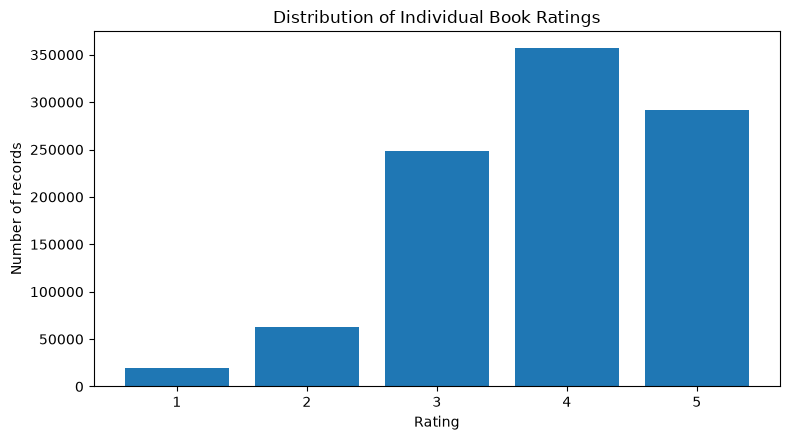

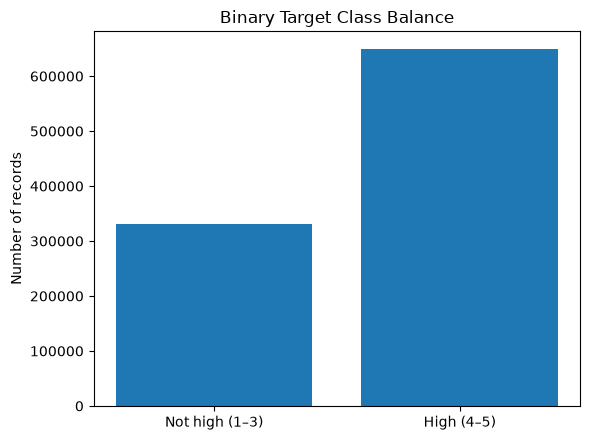

Unique books in ratings: 10000
Unique books in metadata: 10000


In [4]:
rating_distribution = ratings_df[rating_col].value_counts().sort_index()

plt.figure(figsize=(8, 4.5))
plt.bar(rating_distribution.index.astype(str), rating_distribution.values)
plt.title("Distribution of Individual Book Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of records")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "03_rating_distribution.png", dpi=160, bbox_inches="tight")
plt.show()

plt.figure(figsize=(6, 4.5))
plt.bar(
    ["Not high (1–3)", "High (4–5)"],
    [int((ratings_df["high_rating"] == 0).sum()),
     int((ratings_df["high_rating"] == 1).sum())]
)
plt.title("Binary Target Class Balance")
plt.ylabel("Number of records")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "03_target_class_balance.png", dpi=160, bbox_inches="tight")
plt.show()

print("Unique books in ratings:", ratings_df[ratings_book_id_col].nunique())
print("Unique books in metadata:", books_df[books_id_col].nunique())


## 5. Join ratings to metadata and select features

Use descriptive book metadata such as title, authors, language, and publication year when available. Exclude `average_rating` and similar aggregates because they may include the ratings being predicted. User IDs and book IDs are not model features.

In [5]:

# ============================================================
# 5. Join ratings to book metadata using the correct ID
# ============================================================

# Ratings book_id corresponds to books.id (internal ID).
ratings_model = ratings_df.rename(
    columns={"book_id": "model_book_id"}
).copy()

books_model = books_df.rename(
    columns={"id": "model_book_id"}
).copy()

# Keep one metadata record per internal book ID.
books_model = books_model.drop_duplicates(
    subset=["model_book_id"]
)

# Join using the verified internal identifier.
data = ratings_model.merge(
    books_model,
    on="model_book_id",
    how="inner",
    suffixes=("_rating", "_book"),
    validate="many_to_one"
)

print("Ratings records:", len(ratings_model))
print("Joined records:", len(data))
print("Unmatched records:", len(ratings_model) - len(data))
print("Unique books in joined data:", data["model_book_id"].nunique())

assert len(data) == len(ratings_model), (
    "Some rating records did not match book metadata. "
    "Investigate the IDs before proceeding."
)

# Use book metadata as predictors.
# Exclude rating aggregates to avoid target leakage.
lower_cols = {str(c).lower(): c for c in data.columns}

def choose_existing(candidates):
    return [
        lower_cols[c.lower()]
        for c in candidates
        if c.lower() in lower_cols
    ]

blocked = {
    "average_rating", "rating", "high_rating",
    "positive_rating", "user_id", "model_book_id",
    "book_id", "goodreads_book_id", "id",
    "isbn", "isbn13", "best_book_id", "work_id",
    "ratings_1", "ratings_2", "ratings_3",
    "ratings_4", "ratings_5", "work_ratings_count"
}

text_candidates = [
    c for c in choose_existing(
        ["title_book", "original_title", "authors_book"]
    )
    if c.lower() not in blocked
]

categorical_candidates = [
    c for c in choose_existing(
        ["language_code_book", "publisher"]
    )
    if c.lower() not in blocked
]

numeric_candidates = [
    c for c in choose_existing([
        "original_publication_year",
        "work_text_reviews_count",
        "books_count"
    ])
    if c.lower() not in blocked
]

text_candidates = list(dict.fromkeys(text_candidates))
categorical_candidates = list(dict.fromkeys(categorical_candidates))
numeric_candidates = list(dict.fromkeys(numeric_candidates))

print("\nText features:", text_candidates)
print("Categorical features:", categorical_candidates)
print("Numeric features:", numeric_candidates)

if text_candidates:
    data["combined_text"] = (
        data[text_candidates]
        .fillna("")
        .astype(str)
        .agg(" ".join, axis=1)
    )
else:
    data["combined_text"] = ""

# Keep the original target from Section 3.
if "high_rating" not in data.columns:
    data["high_rating"] = (data["rating"] >= 4).astype(int)

# Reapply the configured sample limit, reproducibly.
if MAX_ROWS is not None and len(data) > MAX_ROWS:
    data = data.sample(
        n=MAX_ROWS,
        random_state=RANDOM_STATE
    )

data = data.reset_index(drop=True)

print("\nRows available for modelling:", len(data))
print("High-rating rate:", round(data["high_rating"].mean(), 4))
display(data[[
    "model_book_id", "rating", "high_rating", "combined_text"
]].head())


Ratings records: 980112
Joined records: 980112
Unmatched records: 0
Unique books in joined data: 10000

Text features: ['title_book', 'original_title', 'authors_book']
Categorical features: ['language_code_book']
Numeric features: ['original_publication_year', 'work_text_reviews_count', 'books_count']

Rows available for modelling: 200000
High-rating rate: 0.6603


,model_book_id,rating,high_rating,combined_text
0,3890,5,1,The Power of a Praying Woman The Power of a Pr...
1,3682,3,0,"Lost in Shangri-la: A True Story of Survival, ..."
2,7620,5,1,Ethan Frome and Other Short Fiction Ethan From...
3,2116,4,1,"A Darker Shade of Magic (Shades of Magic, #1) ..."
4,3639,3,0,The 101 Dalmatians (The Hundred and One Dalmat...


## 6. Create training and test sets

A stratified split preserves the target proportions. The same books may appear in both sets, so this evaluates held-out rating records rather than unseen books.

In [6]:
feature_columns = []
if text_candidates:
    feature_columns.append("combined_text")
feature_columns += categorical_candidates + numeric_candidates

X = data[feature_columns].copy()
y = data["high_rating"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Training high-rating rate:", round(y_train.mean(), 4))
print("Testing high-rating rate:", round(y_test.mean(), 4))


Training rows: 160000
Testing rows: 40000
Training high-rating rate: 0.6603
Testing high-rating rate: 0.6604


## 7. Preprocessing and baseline model

In [7]:
def make_one_hot_encoder():
    try:
        return OneHotEncoder(handle_unknown="ignore", min_frequency=2)
    except TypeError:  # compatibility with older scikit-learn
        return OneHotEncoder(handle_unknown="ignore")

transformers = []
if text_candidates:
    transformers.append((
        "text",
        TfidfVectorizer(max_features=30000, ngram_range=(1, 2),
                        min_df=2, sublinear_tf=True),
        "combined_text"
    ))

if categorical_candidates:
    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", make_one_hot_encoder())
    ])
    transformers.append(("categorical", categorical_pipeline, categorical_candidates))

if numeric_candidates:
    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scale", StandardScaler())
    ])
    transformers.append(("numeric", numeric_pipeline, numeric_candidates))

preprocessor = ColumnTransformer(transformers=transformers, remainder="drop")

baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)

print("Baseline accuracy:", round(accuracy_score(y_test, baseline_pred), 4))
print("Baseline F1:", round(f1_score(y_test, baseline_pred, zero_division=0), 4))


Baseline accuracy: 0.6603
Baseline F1: 0.7954


## 8. Train Logistic Regression

In [8]:
model = Pipeline([
    ("preprocess", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000, class_weight="balanced",
        random_state=RANDOM_STATE, solver="liblinear"
    ))
])

model.fit(X_train, y_train)
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]
print("Model training completed.")


Model training completed.


## 9. Evaluate performance

,model,accuracy,precision,recall,f1,roc_auc
0,Majority-class baseline,0.6604,0.6604,1.0000,0.7954,NaN
1,Logistic Regression,0.5853,0.7272,0.5952,0.6546,0.6114


\nClassification report:
                       precision    recall  f1-score   support

Not high rating (1–3)       0.42      0.57      0.48     13586
    High rating (4–5)       0.73      0.60      0.65     26414

             accuracy                           0.59     40000
            macro avg       0.57      0.58      0.57     40000
         weighted avg       0.62      0.59      0.60     40000



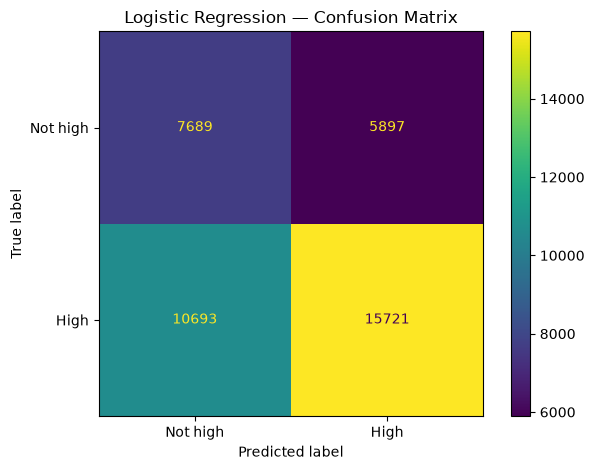

Metrics saved to: c:\Users\Nethmi\Desktop\goodbooks-graph-research\outputs\tables\03_rating_prediction_metrics.csv


In [9]:
def calculate_metrics(model_name, y_true, y_pred, y_prob=None):
    result = {
        "model": model_name,
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0)
    }
    result["roc_auc"] = (
        roc_auc_score(y_true, y_prob)
        if y_prob is not None and len(np.unique(y_true)) == 2
        else np.nan
    )
    return result

metrics_df = pd.DataFrame([
    calculate_metrics("Majority-class baseline", y_test, baseline_pred),
    calculate_metrics("Logistic Regression", y_test, y_pred, y_prob)
])
display(metrics_df.round(4))

print("\\nClassification report:")
print(classification_report(
    y_test, y_pred,
    target_names=["Not high rating (1–3)", "High rating (4–5)"],
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=["Not high", "High"], values_format="d"
)
plt.title("Logistic Regression — Confusion Matrix")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "03_logistic_regression_confusion_matrix.png",
            dpi=160, bbox_inches="tight")
plt.show()

metrics_df.to_csv(TABLES_DIR / "03_rating_prediction_metrics.csv", index=False)
print("Metrics saved to:", TABLES_DIR / "03_rating_prediction_metrics.csv")


## 10. Interpret results and limitations

In [10]:
baseline_row = metrics_df.loc[
    metrics_df["model"] == "Majority-class baseline"
].iloc[0]
model_row = metrics_df.loc[
    metrics_df["model"] == "Logistic Regression"
].iloc[0]

print("RESULT INTERPRETATION")
print("-" * 55)
print(f"Baseline accuracy: {baseline_row['accuracy']:.4f}")
print(f"Logistic Regression accuracy: {model_row['accuracy']:.4f}")
print(f"Precision: {model_row['precision']:.4f}")
print(f"Recall: {model_row['recall']:.4f}")
print(f"F1-score: {model_row['f1']:.4f}")
print(f"ROC-AUC: {model_row['roc_auc']:.4f}")

if model_row["f1"] > baseline_row["f1"]:
    print("\\nThe model improves on the baseline F1-score.")
else:
    print("\\nThe model does not improve on the baseline F1-score. Review the features, target, and model choice.")

print(
    "\\nLimitation: this is a metadata-based binary classification experiment, "
    "not a personalised recommendation model. The random split allows the "
    "same books to occur in both training and testing."
)


RESULT INTERPRETATION
-------------------------------------------------------
Baseline accuracy: 0.6603
Logistic Regression accuracy: 0.5853
Precision: 0.7272
Recall: 0.5952
F1-score: 0.6546
ROC-AUC: 0.6114
\nThe model does not improve on the baseline F1-score. Review the features, target, and model choice.
\nLimitation: this is a metadata-based binary classification experiment, not a personalised recommendation model. The random split allows the same books to occur in both training and testing.


## 11. Save configuration and finish

In [11]:
config = {
    "project": "Goodbooks-10k Book Rating Prediction",
    "target": "high_rating = 1 if rating >= 4 else 0",
    "rating_column": str(rating_col),
    "ratings_book_id_column": str(ratings_book_id_col),
    "books_id_column": str(books_id_col),
    "text_features": [str(c) for c in text_candidates],
    "categorical_features": [str(c) for c in categorical_candidates],
    "numeric_features": [str(c) for c in numeric_candidates],
    "max_rows": MAX_ROWS,
    "actual_rows_used": int(len(data)),
    "test_size": 0.20,
    "random_state": RANDOM_STATE,
    "model": "LogisticRegression(class_weight='balanced')",
    "excluded_feature_types": [
        "user identifiers", "book identifiers", "average rating aggregates"
    ]
}

config_path = TABLES_DIR / "03_rating_prediction_config.json"
with open(config_path, "w", encoding="utf-8") as f:
    json.dump(config, f, indent=2)

print("Configuration saved to:", config_path)
print("Figures directory:", FIGURES_DIR)
print("Tables directory:", TABLES_DIR)
print("Notebook 3 pipeline completed.")


Configuration saved to: c:\Users\Nethmi\Desktop\goodbooks-graph-research\outputs\tables\03_rating_prediction_config.json
Figures directory: c:\Users\Nethmi\Desktop\goodbooks-graph-research\outputs\figures
Tables directory: c:\Users\Nethmi\Desktop\goodbooks-graph-research\outputs\tables
Notebook 3 pipeline completed.


In [12]:

print("Ratings book_id range:")
print(ratings_df["book_id"].min(), ratings_df["book_id"].max())

print("\nBooks internal id range:")
print(books_df["id"].min(), books_df["id"].max())

print("\nBooks book_id range:")
print(books_df["book_id"].min(), books_df["book_id"].max())

ratings_ids = set(ratings_df["book_id"].dropna().astype(int))
books_internal_ids = set(books_df["id"].dropna().astype(int))
books_book_ids = set(books_df["book_id"].dropna().astype(int))

print("\nUnique rating book IDs:", len(ratings_ids))
print("Overlap with books.id:", len(ratings_ids & books_internal_ids))
print("Overlap with books.book_id:", len(ratings_ids & books_book_ids))

print("\nFirst 10 rating IDs:")
print(sorted(ratings_ids)[:10])

print("\nFirst 10 internal book IDs:")
print(sorted(books_internal_ids)[:10])

print("\nFirst 10 books.book_id values:")
print(sorted(books_book_ids)[:10])


Ratings book_id range:
1 10000

Books internal id range:
1 10000

Books book_id range:
1 33288638

Unique rating book IDs: 10000
Overlap with books.id: 10000
Overlap with books.book_id: 812

First 10 rating IDs:
[1, 2, 3, 4, 5, 6, 7, 8, 9, 10]

First 10 internal book IDs:
[1, 2, 3, 4, 5, 6, 7, 8, 9, 10]

First 10 books.book_id values:
[1, 2, 3, 5, 6, 8, 10, 11, 13, 21]


In [13]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Reuse the existing training and test split.
# Random Forest does not accept sparse TF-IDF matrices efficiently,
# so use the structured metadata features for this comparison.
rf_features = categorical_candidates + numeric_candidates

if not rf_features:
    raise ValueError("No structured metadata features are available.")

X_rf = data[rf_features].copy()
y_rf = data["high_rating"].astype(int)

X_rf_train, X_rf_test, y_rf_train, y_rf_test = train_test_split(
    X_rf,
    y_rf,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y_rf
)

rf_preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("onehot", OneHotEncoder(handle_unknown="ignore"))
            ]),
            categorical_candidates
        ),
        (
            "numeric",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median"))
            ]),
            numeric_candidates
        )
    ],
    remainder="drop"
)

rf_model = Pipeline([
    ("preprocess", rf_preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=150,
        max_depth=15,
        min_samples_leaf=10,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

rf_model.fit(X_rf_train, y_rf_train)

rf_pred = rf_model.predict(X_rf_test)
rf_prob = rf_model.predict_proba(X_rf_test)[:, 1]

rf_results = pd.DataFrame([{
    "model": "Random Forest (structured metadata)",
    "accuracy": accuracy_score(y_rf_test, rf_pred),
    "precision": precision_score(
        y_rf_test, rf_pred, zero_division=0
    ),
    "recall": recall_score(
        y_rf_test, rf_pred, zero_division=0
    ),
    "f1": f1_score(y_rf_test, rf_pred, zero_division=0),
    "roc_auc": roc_auc_score(y_rf_test, rf_prob)
}])

display(rf_results.round(4))

rf_results.to_csv(
    TABLES_DIR / "03_random_forest_metrics.csv",
    index=False
)

print("Saved:", TABLES_DIR / "03_random_forest_metrics.csv")


,model,accuracy,precision,recall,f1,roc_auc
0,Random Forest (structured metadata),0.5628,0.7189,0.5548,0.6263,0.5919


Saved: c:\Users\Nethmi\Desktop\goodbooks-graph-research\outputs\tables\03_random_forest_metrics.csv


In [14]:

# ============================================================
# MODEL 4: LINEAR SUPPORT VECTOR MACHINE (SVM)
# ============================================================

from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
import pandas as pd

svm_model = Pipeline([
    ("preprocess", preprocessor),
    ("classifier", LinearSVC(
        class_weight="balanced",
        random_state=RANDOM_STATE,
        max_iter=5000
    ))
])

# Train
svm_model.fit(X_train, y_train)

# Predict
svm_pred = svm_model.predict(X_test)
svm_scores = svm_model.decision_function(X_test)

# Evaluate
svm_results = pd.DataFrame([{
    "model": "Linear SVM",
    "accuracy": accuracy_score(y_test, svm_pred),
    "precision": precision_score(
        y_test, svm_pred, zero_division=0
    ),
    "recall": recall_score(
        y_test, svm_pred, zero_division=0
    ),
    "f1": f1_score(
        y_test, svm_pred, zero_division=0
    ),
    "roc_auc": roc_auc_score(y_test, svm_scores)
}])

print("LINEAR SVM RESULTS")
display(svm_results.round(4))

svm_results.to_csv(
    TABLES_DIR / "03_linear_svm_results.csv",
    index=False
)

print("Results saved to:", TABLES_DIR / "03_linear_svm_results.csv")


LINEAR SVM RESULTS


,model,accuracy,precision,recall,f1,roc_auc
0,Linear SVM,0.5814,0.7245,0.5907,0.6508,0.6062


Results saved to: c:\Users\Nethmi\Desktop\goodbooks-graph-research\outputs\tables\03_linear_svm_results.csv


In [15]:

# ============================================================
# MODEL 5: HISTOGRAM GRADIENT BOOSTING
# ============================================================

from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
import pandas as pd

# Select structured features
gb_features = categorical_candidates + numeric_candidates

if not numeric_candidates:
    raise ValueError(
        "Gradient Boosting requires at least one numeric feature."
    )

X_gb_train = X_train[gb_features].copy()
X_gb_test = X_test[gb_features].copy()

# Preprocess categorical features using training data only
if categorical_candidates:
    for col in categorical_candidates:
        X_gb_train[col] = X_gb_train[col].fillna("Unknown").astype(str)
        X_gb_test[col] = X_gb_test[col].fillna("Unknown").astype(str)

    encoder = OrdinalEncoder(
        handle_unknown="use_encoded_value",
        unknown_value=-1
    )

    X_gb_train[categorical_candidates] = encoder.fit_transform(
        X_gb_train[categorical_candidates]
    )

    X_gb_test[categorical_candidates] = encoder.transform(
        X_gb_test[categorical_candidates]
    )

# Impute numeric features using training data only
if numeric_candidates:
    imputer = SimpleImputer(strategy="median")

    X_gb_train[numeric_candidates] = imputer.fit_transform(
        X_gb_train[numeric_candidates]
    )

    X_gb_test[numeric_candidates] = imputer.transform(
        X_gb_test[numeric_candidates]
    )

# Train
gb_model = HistGradientBoostingClassifier(
    max_iter=150,
    learning_rate=0.08,
    max_leaf_nodes=15,
    l2_regularization=1.0,
    random_state=RANDOM_STATE
)

gb_model.fit(X_gb_train, y_train)

# Predict
gb_pred = gb_model.predict(X_gb_test)
gb_prob = gb_model.predict_proba(X_gb_test)[:, 1]

# Evaluate
gb_results = pd.DataFrame([{
    "model": "Histogram Gradient Boosting",
    "accuracy": accuracy_score(y_test, gb_pred),
    "precision": precision_score(
        y_test, gb_pred, zero_division=0
    ),
    "recall": recall_score(
        y_test, gb_pred, zero_division=0
    ),
    "f1": f1_score(
        y_test, gb_pred, zero_division=0
    ),
    "roc_auc": roc_auc_score(y_test, gb_prob)
}])

print("HISTOGRAM GRADIENT BOOSTING RESULTS")
display(gb_results.round(4))

gb_results.to_csv(
    TABLES_DIR / "03_hist_gradient_boosting_results.csv",
    index=False
)

print(
    "Results saved to:",
    TABLES_DIR / "03_hist_gradient_boosting_results.csv"
)


HISTOGRAM GRADIENT BOOSTING RESULTS


,model,accuracy,precision,recall,f1,roc_auc
0,Histogram Gradient Boosting,0.6606,0.6609,0.9983,0.7953,0.5629


Results saved to: c:\Users\Nethmi\Desktop\goodbooks-graph-research\outputs\tables\03_hist_gradient_boosting_results.csv


In [16]:

# ============================================================
# FINAL FIVE-MODEL COMPARISON
# ============================================================

all_model_results = pd.concat(
    [
        metrics_df,
        rf_results,
        svm_results,
        gb_results
    ],
    ignore_index=True
)

all_model_results = all_model_results[
    ["model", "accuracy", "precision", "recall", "f1", "roc_auc"]
].drop_duplicates(subset=["model"], keep="last")

all_model_results = all_model_results.sort_values(
    by="roc_auc",
    ascending=False,
    na_position="last"
).reset_index(drop=True)

display(all_model_results.round(4))

comparison_path = TABLES_DIR / "03_final_five_model_comparison.csv"

all_model_results.to_csv(
    comparison_path,
    index=False
)

print("Final comparison saved to:", comparison_path)


,model,accuracy,precision,recall,f1,roc_auc
0,Logistic Regression,0.5853,0.7272,0.5952,0.6546,0.6114
1,Linear SVM,0.5814,0.7245,0.5907,0.6508,0.6062
2,Random Forest (structured metadata),0.5628,0.7189,0.5548,0.6263,0.5919
3,Histogram Gradient Boosting,0.6606,0.6609,0.9983,0.7953,0.5629
4,Majority-class baseline,0.6604,0.6604,1.0000,0.7954,NaN


Final comparison saved to: c:\Users\Nethmi\Desktop\goodbooks-graph-research\outputs\tables\03_final_five_model_comparison.csv


In [17]:
# Display variables currently available in the notebook
print("Available model and test-data variables:\n")

for name in sorted(globals()):
    if any(key in name.lower() for key in [
        "model", "clf", "log_reg", "logistic",
        "gb", "test", "pred", "pipeline"
    ]):
        obj = globals()[name]
        print(f"{name}: {type(obj).__name__}")

Available model and test-data variables:

LogisticRegression: type
Pipeline: ABCMeta
X_gb_test: DataFrame
X_gb_train: DataFrame
X_rf_test: DataFrame
X_test: DataFrame
all_model_results: DataFrame
baseline_pred: ndarray
books_model: DataFrame
categorical_pipeline: Pipeline
gb_features: list
gb_model: HistGradientBoostingClassifier
gb_pred: ndarray
gb_prob: ndarray
gb_results: DataFrame
model: Pipeline
model_row: Series
numeric_pipeline: Pipeline
ratings_model: DataFrame
rf_model: Pipeline
rf_pred: ndarray
svm_model: Pipeline
svm_pred: ndarray
train_test_split: function
y_pred: ndarray
y_rf_test: Series
y_test: Series



Logistic Regression

Classification Report:
                    precision    recall  f1-score   support

Lower Rating (1–3)       0.42      0.57      0.48     13586
 High Rating (4–5)       0.73      0.60      0.65     26414

          accuracy                           0.59     40000
         macro avg       0.57      0.58      0.57     40000
      weighted avg       0.62      0.59      0.60     40000

Confusion Matrix:
[[ 7689  5897]
 [10693 15721]]


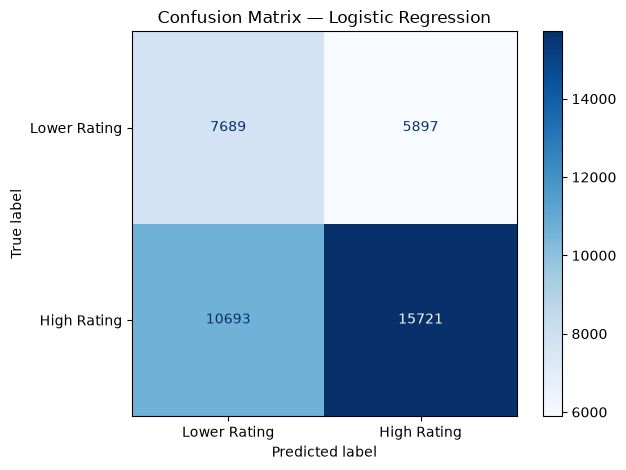


Histogram Gradient Boosting

Classification Report:
                    precision    recall  f1-score   support

Lower Rating (1–3)       0.54      0.00      0.01     13586
 High Rating (4–5)       0.66      1.00      0.80     26414

          accuracy                           0.66     40000
         macro avg       0.60      0.50      0.40     40000
      weighted avg       0.62      0.66      0.53     40000

Confusion Matrix:
[[   55 13531]
 [   46 26368]]


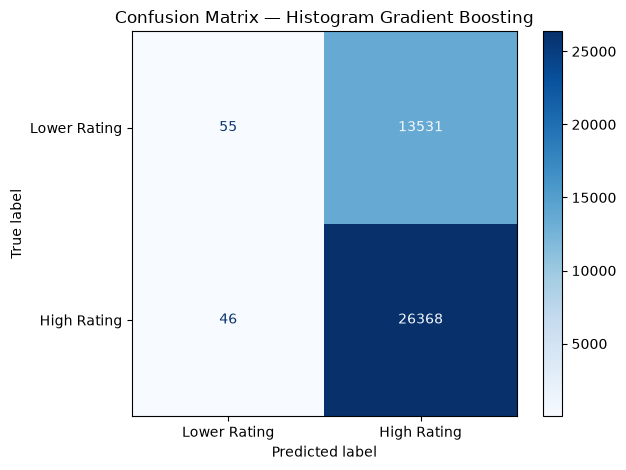

In [18]:
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    classification_report,
    confusion_matrix
)
import matplotlib.pyplot as plt

# Use the existing trained models
models_to_evaluate = {
    "Logistic Regression": (model, X_test),
    "Histogram Gradient Boosting": (gb_model, X_gb_test)
}

for model_name, (trained_model, test_features) in models_to_evaluate.items():

    # Generate predictions
    predictions = trained_model.predict(test_features)

    # Use the matching target labels
    actual = y_test

    print(f"\n{'=' * 60}")
    print(model_name)
    print("=" * 60)

    print("\nClassification Report:")
    print(classification_report(
        actual,
        predictions,
        labels=[0, 1],
        target_names=["Lower Rating (1–3)", "High Rating (4–5)"],
        zero_division=0
    ))

    print("Confusion Matrix:")
    print(confusion_matrix(actual, predictions, labels=[0, 1]))

    ConfusionMatrixDisplay.from_predictions(
        actual,
        predictions,
        labels=[0, 1],
        display_labels=["Lower Rating", "High Rating"],
        cmap="Blues"
    )

    plt.title(f"Confusion Matrix — {model_name}")
    plt.tight_layout()
    plt.show()

### Interpretation and Limitations of Classification Results

The classification experiments evaluated five approaches for predicting whether a book rating was high (4–5) or lower (1–3). Logistic Regression achieved the highest ROC-AUC among the trained models (0.6114), followed by Linear SVM (0.6062) and Random Forest (0.5919).

The confusion matrix for Logistic Regression showed that the model identified both rating classes, although classification errors remained substantial. It correctly classified 7,689 lower-rating observations and 15,721 high-rating observations out of 40,000 test observations.

Histogram Gradient Boosting achieved 66.06% accuracy but correctly identified only 55 of the 13,586 lower-rating observations. This indicates a strong tendency to predict the majority high-rating class. The majority-class baseline also achieved approximately 66% accuracy, demonstrating the limitations of accuracy as the sole evaluation metric.

Overall, the results indicate limited predictive discrimination using the selected book-title, author, language, and structured metadata features. The experiments provide a useful baseline for investigating book-rating prediction, but the models should not be considered reliable standalone recommendation systems. Further feature engineering, class-imbalance handling, and evaluation would be needed to improve predictive performance.